# Problema 5 - Segmentação de clientes de um distribuidor atacadista com k-Means (UCI Wholesale Customers, 440 clientes, 6 categorias de gasto anual).
IMPORTANTE: Channel e Region NÃO entram no agrupamento. Eles são separados
logo no início e só voltam na validação externa da Tarefa 5.


In [1]:
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 200)       # tabelas largas sem quebrar colunas
pd.set_option("display.max_columns", None)

# ----------------------------------------------------------------------------
# Configurações gerais
# ----------------------------------------------------------------------------
BASE = Path.cwd()  # abra o notebook DENTRO da pasta do problema (ao lado de dados/)
ARQ_DADOS = BASE / "dados" / "Wholesale customers data.csv"
PASTA_FIG = BASE / "figuras"
PASTA_FIG.mkdir(exist_ok=True)

SEED = 42
GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
NOME_CANAL = {1: "Horeca", 2: "Retail"}
NOME_REGIAO = {1: "Lisboa", 2: "Porto", 3: "Outras"}
K_MIN, K_MAX = 2, 10

# Valor de k adotado (decisão justificada na Tarefa 3 e no relatório):
#   * silhueta: k=2 (0,290) e k=3 (0,259) são os melhores; de k=4 em diante
#     ela cai para ~0,19-0,20 (estrutura fraca);
#   * inércia: sem cotovelo nítido; a queda relativa vai de 15,8% (2->3) para
#     10,7% (3->4) e segue decrescendo devagar;
#   * interpretação comercial: k=3 separa três perfis distintos e acionáveis.
K_ESCOLHIDO = 3


def titulo(texto):
    """Imprime um cabeçalho para separar as seções na saída do terminal."""
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def nomear(z_centroide):
    """Dá um nome comercial a um grupo a partir do centroide em escala Z.

    z_centroide: Series (categoria -> valor em desvios padrão da média geral).
    As regras olham as categorias em que o grupo gasta bem acima (>= +0,3) ou
    bem abaixo (<= -0,5) da média dos clientes.
    """
    alto = [c for c in GASTOS if z_centroide[c] >= 0.3]
    baixo = [c for c in GASTOS if z_centroide[c] <= -0.5]
    if len(alto) >= 5:
        return "Grandes compradores multicategoria"
    if {"Milk", "Grocery", "Detergents_Paper"} <= set(alto) and {"Fresh", "Frozen"} <= set(baixo):
        return "Mercearia, laticínios e limpeza (varejo de bairro)"
    if {"Milk", "Grocery", "Detergents_Paper"} <= set(baixo) and (
            z_centroide["Fresh"] > 0 or z_centroide["Frozen"] > 0):
        return "Perfil restaurante: frescos e congelados, pouca mercearia e limpeza"
    return "Perfil misto (destaque em: " + ", ".join(alto or ["nenhuma"]) + ")"

## CARREGAMENTO

In [2]:
titulo("0. Carregamento dos dados")

df = pd.read_csv(ARQ_DADOS)
print(f"Formato (linhas, colunas): {df.shape}")
print(f"Valores ausentes: {df.isna().sum().sum()} | linhas duplicadas: {df.duplicated().sum()}")
print("\nColunas:", list(df.columns))

# Separa Channel e Region do restante (uso só na validação externa, Tarefa 5)
canal = df["Channel"]
regiao = df["Region"]
X = df[GASTOS].copy()
print("\nClientes por canal :", {NOME_CANAL[k]: int(v) for k, v in canal.value_counts().sort_index().items()})
print("Clientes por região:", {NOME_REGIAO[k]: int(v) for k, v in regiao.value_counts().sort_index().items()})


0. Carregamento dos dados
Formato (linhas, colunas): (440, 8)
Valores ausentes: 0 | linhas duplicadas: 0

Colunas: ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Clientes por canal : {'Horeca': 298, 'Retail': 142}
Clientes por região: {'Lisboa': 77, 'Porto': 47, 'Outras': 316}


## TAREFA 1 - Preparação: estatísticas, log, padronização e correlação

In [3]:
titulo("TAREFA 1 - Estatísticas descritivas dos seis gastos (escala original)")

estat = pd.DataFrame({
    "média": X.mean(),
    "mediana": X.median(),
    "desvio_padrão": X.std(),
    "mínimo": X.min(),
    "máximo": X.max(),
    "assimetria": X.skew(),
})
print(estat.round(2))
print("\n(média > mediana e assimetria positiva alta = cauda longa à direita)")

# Contagem de outliers pela regra de Tukey (fora de [Q1 - 1,5 IQR, Q3 + 1,5 IQR])
def contar_outliers(tabela):
    q1, q3 = tabela.quantile(0.25), tabela.quantile(0.75)
    iqr = q3 - q1
    return ((tabela < q1 - 1.5 * iqr) | (tabela > q3 + 1.5 * iqr)).sum()


TAREFA 1 - Estatísticas descritivas dos seis gastos (escala original)
                     média  mediana  desvio_padrão  mínimo  máximo  assimetria
Fresh             12000.30   8504.0       12647.33       3  112151        2.56
Milk               5796.27   3627.0        7380.38      55   73498        4.05
Grocery            7951.28   4755.5        9503.16       3   92780        3.59
Frozen             3071.93   1526.0        4854.67      25   60869        5.91
Detergents_Paper   2881.49    816.5        4767.85       3   40827        3.63
Delicassen         1524.87    965.5        2820.11       3   47943       11.15

(média > mediana e assimetria positiva alta = cauda longa à direita)


In [4]:
# --- Transformação logarítmica x' = log(1 + x) ---------------------------------
X_log = np.log1p(X)
estat_log = pd.DataFrame({
    "assimetria_antes": X.skew(),
    "assimetria_depois": X_log.skew(),
    "outliers_antes": contar_outliers(X),
    "outliers_depois": contar_outliers(X_log),
})
print("\nEfeito da transformação log(1 + x):")
print(estat_log.round(2))


Efeito da transformação log(1 + x):
                  assimetria_antes  assimetria_depois  outliers_antes  outliers_depois
Fresh                         2.56              -1.58              20               16
Milk                          4.05              -0.22              28                4
Grocery                       3.59              -0.67              24                2
Frozen                        5.91              -0.35              43               10
Detergents_Paper              3.63              -0.24              30                2
Delicassen                   11.15              -1.09              27               14


In [5]:
# --- Padronização Z-score (média 0, desvio 1) ----------------------------------
# Não há divisão treino/teste neste problema (Tarefa 2), então o padronizador
# é ajustado com todos os 440 clientes.
escalador = StandardScaler()
Z = escalador.fit_transform(X_log)
print("\nApós Z-score: médias ≈ 0 e desvios = 1 em todas as colunas:")
print(pd.DataFrame({"média": Z.mean(axis=0), "desvio padrão": Z.std(axis=0)},
                   index=GASTOS).T.round(4))


Após Z-score: médias ≈ 0 e desvios = 1 em todas as colunas:
               Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
média            0.0  -0.0     -0.0     0.0              -0.0        -0.0
desvio padrão    1.0   1.0      1.0     1.0               1.0         1.0


In [6]:
# --- Por que padronizar? Quanto cada coluna pesa na distância euclidiana --------
# A distância euclidiana soma os quadrados das diferenças; em média, cada
# coluna contribui na proporção da sua VARIÂNCIA.
peso = pd.DataFrame({
    "bruto": X.var() / X.var().sum(),
    "só log": X_log.var() / X_log.var().sum(),
    "log + Z-score": pd.Series(Z.var(axis=0, ddof=1), index=GASTOS) / Z.var(axis=0, ddof=1).sum(),
})
print("\nParticipação de cada categoria na variância total (= no peso da distância):")
print((peso * 100).round(1).astype(str) + " %")


Participação de cada categoria na variância total (= no peso da distância):
                   bruto  só log log + Z-score
Fresh             44.6 %  20.0 %        16.7 %
Milk              15.2 %  10.8 %        16.7 %
Grocery           25.2 %  11.4 %        16.7 %
Frozen             6.6 %  15.2 %        16.7 %
Detergents_Paper   6.3 %  27.0 %        16.7 %
Delicassen         2.2 %  15.5 %        16.7 %


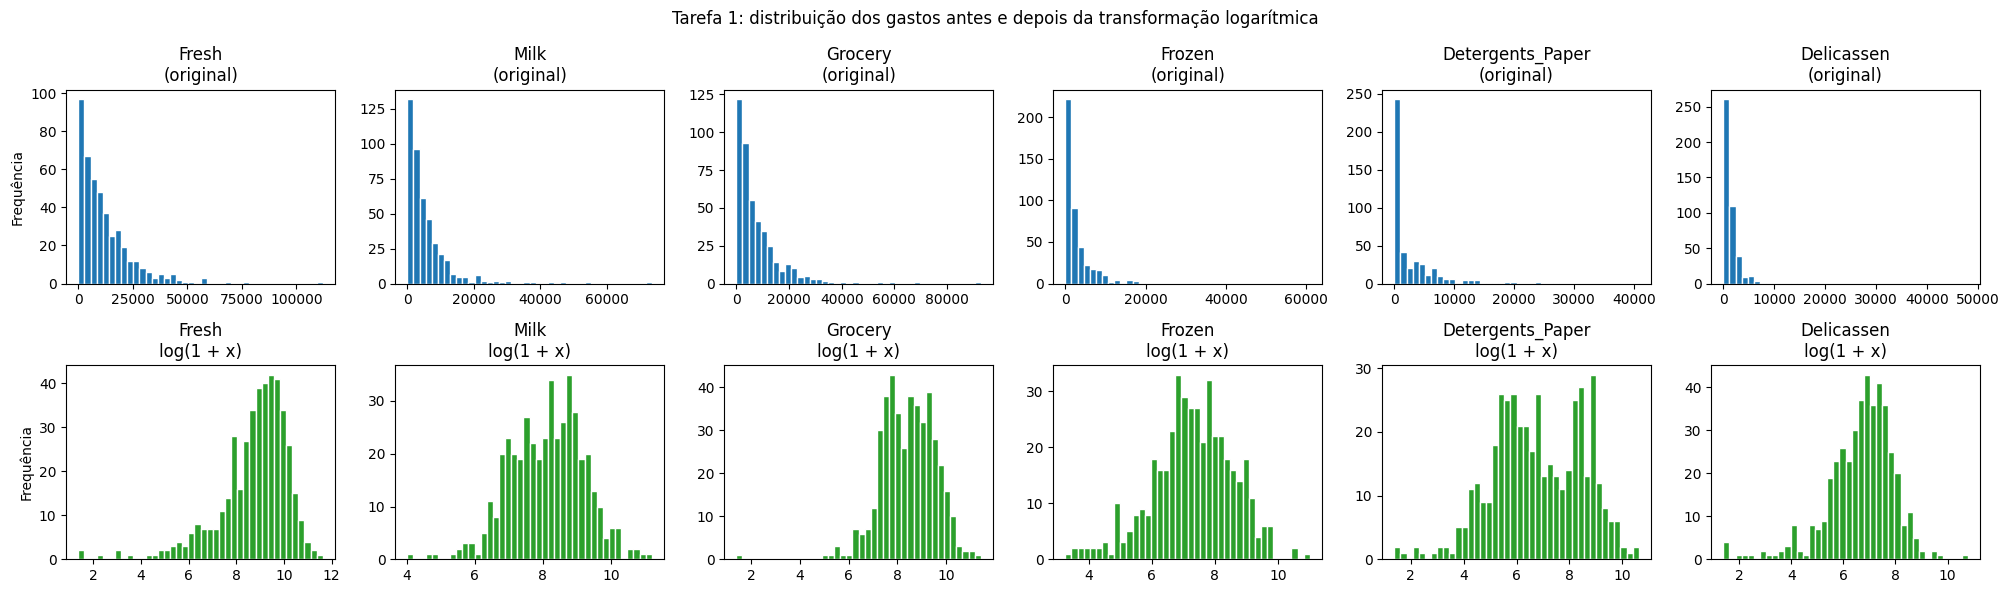

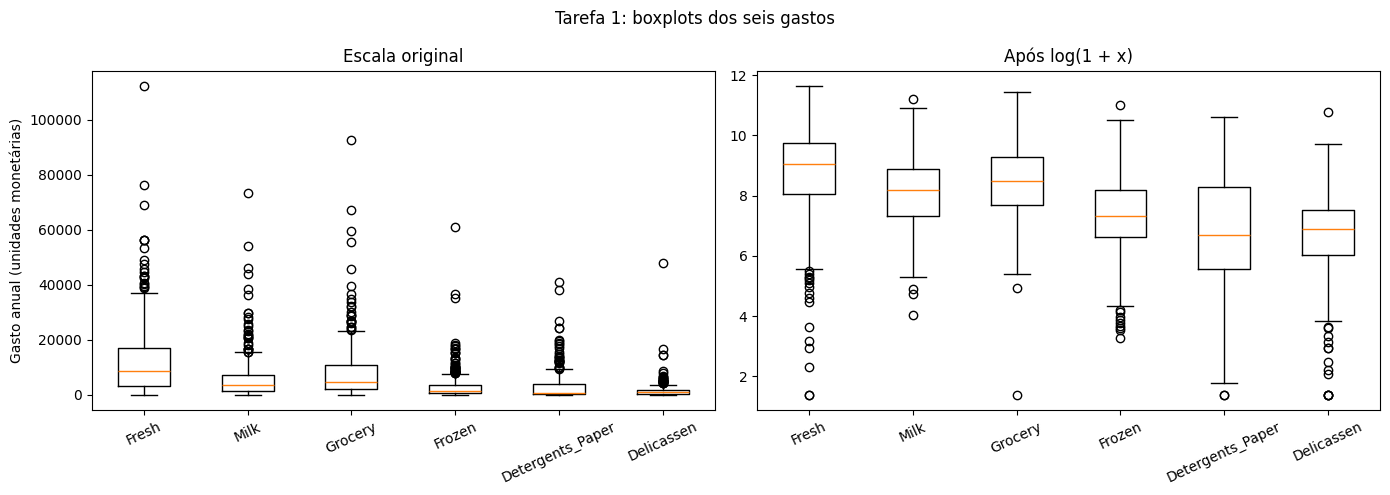

In [7]:
# --- Figuras: histogramas e boxplots (antes e depois do log) ---------------------
fig, eixos = plt.subplots(2, 6, figsize=(20, 6))
for j, c in enumerate(GASTOS):
    eixos[0, j].hist(X[c], bins=40, color="tab:blue", edgecolor="white")
    eixos[0, j].set_title(f"{c}\n(original)")
    eixos[1, j].hist(X_log[c], bins=40, color="tab:green", edgecolor="white")
    eixos[1, j].set_title(f"{c}\nlog(1 + x)")
eixos[0, 0].set_ylabel("Frequência")
eixos[1, 0].set_ylabel("Frequência")
fig.suptitle("Tarefa 1: distribuição dos gastos antes e depois da transformação logarítmica")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t1_histogramas.png", dpi=130)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].boxplot([X[c] for c in GASTOS], tick_labels=GASTOS)
eixos[0].set_title("Escala original")
eixos[0].set_ylabel("Gasto anual (unidades monetárias)")
eixos[1].boxplot([X_log[c] for c in GASTOS], tick_labels=GASTOS)
eixos[1].set_title("Após log(1 + x)")
for ax in eixos:
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Tarefa 1: boxplots dos seis gastos")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t1_boxplots.png", dpi=130)
plt.show()


Matriz de correlação (Pearson) - escala ORIGINAL:
                  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Fresh             1.000  0.101   -0.012   0.346            -0.102       0.245
Milk              0.101  1.000    0.728   0.124             0.662       0.406
Grocery          -0.012  0.728    1.000  -0.040             0.925       0.205
Frozen            0.346  0.124   -0.040   1.000            -0.132       0.391
Detergents_Paper -0.102  0.662    0.925  -0.132             1.000       0.069
Delicassen        0.245  0.406    0.205   0.391             0.069       1.000

Matriz de correlação (Pearson) - após log(1 + x):
                  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Fresh             1.000 -0.021   -0.133   0.386            -0.159       0.256
Milk             -0.021  1.000    0.761  -0.055             0.679       0.342
Grocery          -0.133  0.761    1.000  -0.165             0.797       0.240
Frozen            0.386 -0.055   -0.165 

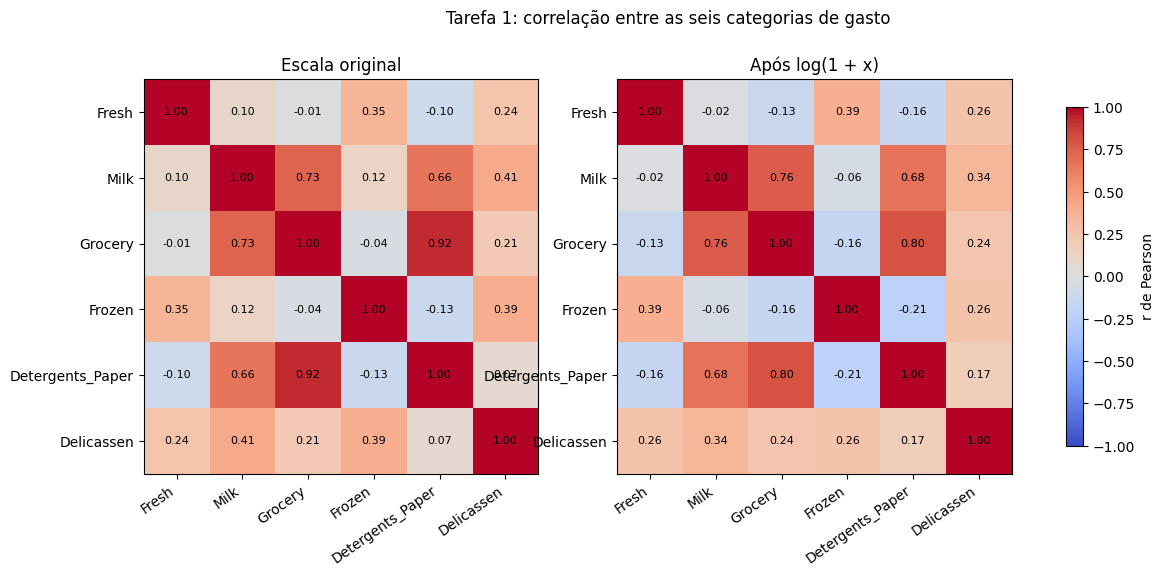

In [8]:
# --- Matriz de correlação entre as seis categorias ------------------------------
corr_bruta = X.corr()
corr_log = X_log.corr()
print("\nMatriz de correlação (Pearson) - escala ORIGINAL:")
print(corr_bruta.round(3))
print("\nMatriz de correlação (Pearson) - após log(1 + x):")
print(corr_log.round(3))
print(f"\nPar Grocery x Detergents_Paper: r = {corr_bruta.loc['Grocery', 'Detergents_Paper']:.3f} "
      f"(original) | r = {corr_log.loc['Grocery', 'Detergents_Paper']:.3f} (após log)")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, mat, nome in zip(eixos, (corr_bruta, corr_log), ("Escala original", "Após log(1 + x)")):
    im = ax.imshow(mat.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(6), GASTOS, rotation=35, ha="right")
    ax.set_yticks(range(6), GASTOS)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(nome)
fig.colorbar(im, ax=eixos, shrink=0.8, label="r de Pearson")
fig.suptitle("Tarefa 1: correlação entre as seis categorias de gasto")
fig.savefig(PASTA_FIG / "t1_correlacao.png", dpi=130, bbox_inches="tight")
plt.show()

## TAREFA 2 - Ausência de divisão treino/teste (discussão)

In [10]:
# * No aprendizado SUPERVISIONADO existe um rótulo conhecido; separar um teste
#   serve para estimar o erro de generalização sobre rótulos que o modelo
#   nunca viu. Aqui NÃO há rótulo, logo não há "erro" a estimar nem gabarito.
# * O k-Means não faz previsões a serem conferidas: ele descreve a estrutura
#   dos próprios dados (e o objetivo é segmentar ESTES 440 clientes).
# * A dificuldade central: sem gabarito, como dizer que uma partição é "boa"?
#   Usam-se critérios INTERNOS (inércia, silhueta), validação EXTERNA com
#   variáveis não usadas (Tarefa 5) e, sobretudo, a utilidade comercial.
# (A discussão completa está no relatório.)

## TAREFA 3 - Escolha do número de grupos (k = 2 a 10)


TAREFA 3 - Inércia (cotovelo) e silhueta para k = 2..10
      inércia  silhueta  queda_inércia_%
k                                       
2   1844.0641    0.2903              NaN
3   1553.4213    0.2594          15.7610
4   1386.8627    0.1885          10.7220
5   1266.1494    0.1916           8.7041
6   1174.7586    0.2009           7.2180
7   1086.3587    0.1958           7.5249
8   1028.4862    0.1852           5.3272
9    973.1415    0.1965           5.3812
10   931.9985    0.1905           4.2279

Cotovelo pelo método da corda: k = 5 (distâncias: {2: 0.0, 3: 0.137, 4: 0.178, 5: 0.183, 6: 0.165, 7: 0.145, 8: 0.102, 9: 0.056, 10: 0.0})
-> a curva é suave, sem cotovelo nítido: as distâncias de k=3 a k=5 são parecidas.
Melhor silhueta: k = 2 (0.2903)
Inércia estritamente decrescente com k? True

k ADOTADO: 3 (silhueta = 0.2594, inércia = 1553.4)


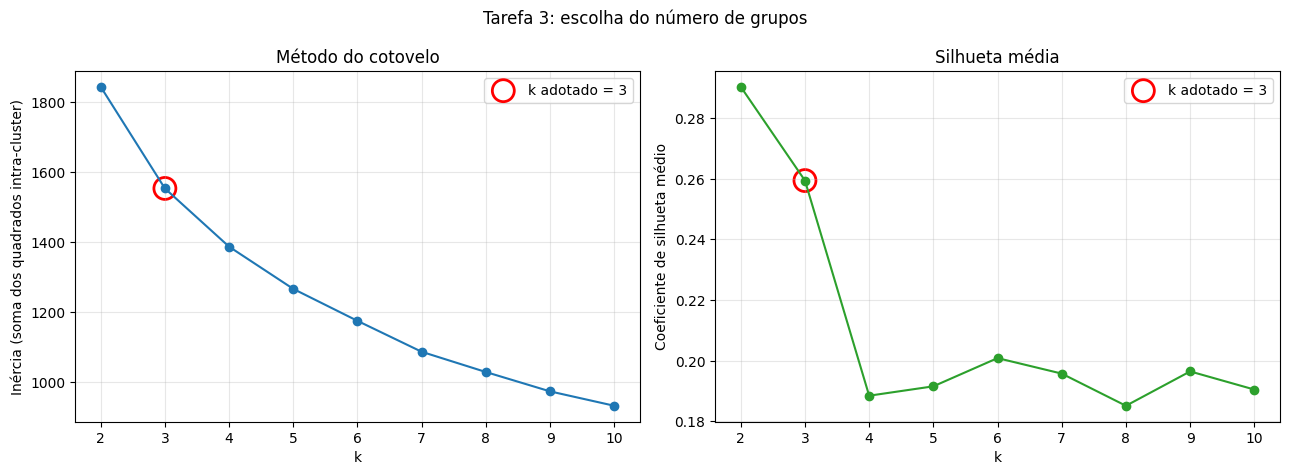


Caso limite k = n = 440: inércia = 0.000000
Silhueta com k = n não é definida (ValueError): Number of labels is 440. Valid values are 2 to n_samples - 1 (inclusive)

Silhueta por grupo (k = 3):
    mean  count
0  0.121     80
1  0.282    147
2  0.296    213
Clientes com silhueta negativa (talvez no grupo errado): 23 de 440 (5.2%)


In [11]:
titulo("TAREFA 3 - Inércia (cotovelo) e silhueta para k = 2..10")

ks = list(range(K_MIN, K_MAX + 1))
inercias, silhuetas = [], []
for k in ks:
    # k-means++ com 10 reinícios (n_init=10): fica com a melhor inércia
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Z)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(Z, km.labels_))

tab_k = pd.DataFrame({"k": ks, "inércia": inercias, "silhueta": silhuetas}).set_index("k")
tab_k["queda_inércia_%"] = (-tab_k["inércia"].pct_change() * 100)
print(tab_k.round(4))

# Cotovelo: ponto da curva mais distante da reta que liga o primeiro ao último
# ponto (curva normalizada para [0, 1]).
x_n = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
y_n = (np.array(inercias) - min(inercias)) / (max(inercias) - min(inercias))
dist_corda = np.abs(y_n - (1 - x_n)) / np.sqrt(2)
k_cotovelo = ks[int(np.argmax(dist_corda))]
print(f"\nCotovelo pelo método da corda: k = {k_cotovelo} "
      f"(distâncias: {dict(zip(ks, dist_corda.round(3).tolist()))})")
print("-> a curva é suave, sem cotovelo nítido: as distâncias de k=3 a k=5 são parecidas.")

k_sil = ks[int(np.argmax(silhuetas))]
print(f"Melhor silhueta: k = {k_sil} ({max(silhuetas):.4f})")
print(f"Inércia estritamente decrescente com k? {all(np.diff(inercias) < 0)}")
print(f"\nk ADOTADO: {K_ESCOLHIDO} (silhueta = {tab_k.loc[K_ESCOLHIDO, 'silhueta']:.4f}, "
      f"inércia = {tab_k.loc[K_ESCOLHIDO, 'inércia']:.1f})")

# Figuras: cotovelo e silhueta
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
eixos[0].plot(ks, inercias, marker="o")
eixos[0].scatter([K_ESCOLHIDO], [tab_k.loc[K_ESCOLHIDO, "inércia"]], s=250,
                 facecolors="none", edgecolors="red", linewidths=2, label=f"k adotado = {K_ESCOLHIDO}")
eixos[0].set_xlabel("k")
eixos[0].set_ylabel("Inércia (soma dos quadrados intra-cluster)")
eixos[0].set_title("Método do cotovelo")
eixos[0].legend()
eixos[0].grid(alpha=0.3)
eixos[1].plot(ks, silhuetas, marker="o", color="tab:green")
eixos[1].scatter([K_ESCOLHIDO], [tab_k.loc[K_ESCOLHIDO, "silhueta"]], s=250,
                 facecolors="none", edgecolors="red", linewidths=2, label=f"k adotado = {K_ESCOLHIDO}")
eixos[1].set_xlabel("k")
eixos[1].set_ylabel("Coeficiente de silhueta médio")
eixos[1].set_title("Silhueta média")
eixos[1].legend()
eixos[1].grid(alpha=0.3)
fig.suptitle("Tarefa 3: escolha do número de grupos")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t3_cotovelo_silhueta.png", dpi=150)
plt.show()

# Caso limite: k = número de amostras -> cada cliente vira o próprio centroide
km_n = KMeans(n_clusters=len(Z), n_init=1, random_state=SEED).fit(Z)
print(f"\nCaso limite k = n = {len(Z)}: inércia = {km_n.inertia_:.6f}")
try:
    silhouette_score(Z, km_n.labels_)
except ValueError as erro:
    print(f"Silhueta com k = n não é definida (ValueError): {erro}")

# Silhueta por amostra para o k adotado
km_k = KMeans(n_clusters=K_ESCOLHIDO, init="k-means++", n_init=10, random_state=SEED).fit(Z)
s_amostra = silhouette_samples(Z, km_k.labels_)
print(f"\nSilhueta por grupo (k = {K_ESCOLHIDO}):")
print(pd.Series(s_amostra).groupby(km_k.labels_).agg(["mean", "count"]).round(3))
print(f"Clientes com silhueta negativa (talvez no grupo errado): "
      f"{(s_amostra < 0).sum()} de {len(Z)} ({(s_amostra < 0).mean():.1%})")

## TAREFA 4 - Inicialização e convergência (random x k-means++)


TAREFA 4 - Dez execuções com init='random' e init='k-means++' (n_init=1)

--- k = 3 (adotado) ---
Inércia final de cada uma das 10 execuções (sementes 0 a 9):
                 0        1        2        3        4        5        6        7        8        9
random     1553.39  1553.45  1582.23  1553.80  1553.45  1626.55  1582.18  1553.45  1580.23  1553.42
k-means++  1553.77  1553.45  1553.34  1582.23  1582.23  1582.23  1553.75  1580.03  1553.45  1553.45

Resumo:
            mínima     média    máxima  desvio padrão  amplitude (máx-mín)  execuções a <= 0,1% do melhor  execuções > 1% acima do melhor  iterações (média)
random     1553.39  1569.214  1626.554         24.107               73.164                            6.0                             4.0               15.4
k-means++  1553.34  1564.791  1582.228         14.548               28.889                            6.0                             4.0               16.2

--- k = 8 (complementar) ---
Inércia final de cada uma das 

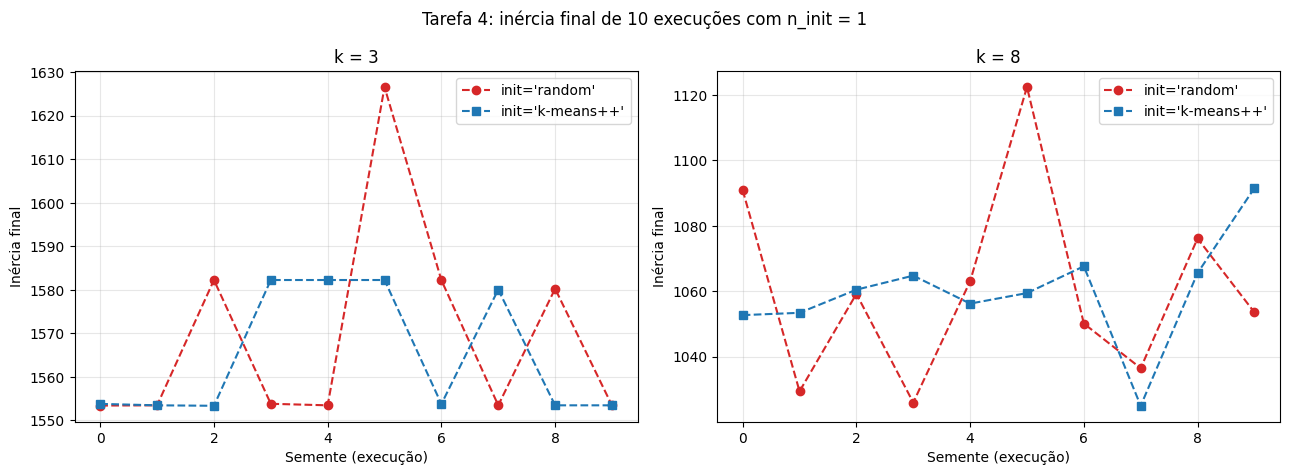

In [12]:
titulo("TAREFA 4 - Dez execuções com init='random' e init='k-means++' (n_init=1)")

SEMENTES = list(range(10))


def rodar_inicializacoes(k):
    """10 execuções de cada tipo de inicialização, com 1 única partida cada."""
    saida = {}
    for init in ("random", "k-means++"):
        modelos = [KMeans(n_clusters=k, init=init, n_init=1, random_state=s).fit(Z) for s in SEMENTES]
        saida[init] = {
            "inercias": np.array([m.inertia_ for m in modelos]),
            "iteracoes": np.array([m.n_iter_ for m in modelos]),
        }
    return saida


def resumir(saida):
    melhor_global = min(v["inercias"].min() for v in saida.values())
    linhas = {}
    for init, v in saida.items():
        i = v["inercias"]
        linhas[init] = {
            "mínima": i.min(), "média": i.mean(), "máxima": i.max(),
            "desvio padrão": i.std(ddof=1), "amplitude (máx-mín)": i.max() - i.min(),
            "execuções a <= 0,1% do melhor": int((i <= melhor_global * 1.001).sum()),
            "execuções > 1% acima do melhor": int((i > melhor_global * 1.01).sum()),
            "iterações (média)": v["iteracoes"].mean(),
        }
    return pd.DataFrame(linhas).T


resultados_init = {}
for k in (K_ESCOLHIDO, 8):  # k adotado + k maior (mais mínimos locais)
    saida = rodar_inicializacoes(k)
    resultados_init[k] = saida
    print(f"\n--- k = {k} " + ("(adotado)" if k == K_ESCOLHIDO else "(complementar)") + " ---")
    print("Inércia final de cada uma das 10 execuções (sementes 0 a 9):")
    print(pd.DataFrame({init: v["inercias"] for init, v in saida.items()},
                       index=SEMENTES).round(2).T)
    print("\nResumo:")
    print(resumir(saida).round(3))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)
for ax, k in zip(eixos, (K_ESCOLHIDO, 8)):
    for init, cor, marc in (("random", "tab:red", "o"), ("k-means++", "tab:blue", "s")):
        ax.plot(SEMENTES, resultados_init[k][init]["inercias"], marker=marc, ls="--",
                color=cor, label=f"init='{init}'")
    ax.set_xlabel("Semente (execução)")
    ax.set_ylabel("Inércia final")
    ax.set_title(f"k = {k}")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Tarefa 4: inércia final de 10 execuções com n_init = 1")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t4_inicializacao.png", dpi=150)
plt.show()

## TAREFA 5 - Interpretação e validação dos grupos

In [13]:
titulo(f"TAREFA 5 - Interpretação e validação externa (k = {K_ESCOLHIDO})")

rotulos = km_k.labels_
tamanhos = np.bincount(rotulos)
print("Tamanho dos grupos:", dict(enumerate(tamanhos.tolist())))


TAREFA 5 - Interpretação e validação externa (k = 3)
Tamanho dos grupos: {0: 80, 1: 147, 2: 213}


Grupo 0: Mercearia, laticínios e limpeza (varejo de bairro)
Grupo 1: Grandes compradores multicategoria
Grupo 2: Perfil restaurante: frescos e congelados, pouca mercearia e limpeza

Centroides em ESCALA Z (desvios padrão em relação à média geral):
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  -1.18  0.48     0.68   -1.14              0.78       -0.70
1   0.41  0.80     0.74    0.30              0.66        0.68
2   0.16 -0.73    -0.76    0.22             -0.75       -0.21

Centroides revertidos para a ESCALA ORIGINAL (típico do grupo):
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0   1095  5635     9851     344              3392         318
1  11287  7972    10520    2168              2762        1906
2   7869  1529     1985    1976               246         602

Médias aritméticas por grupo (escala original, para comparação):
   Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0   2899   7136    12570     607              5554         783

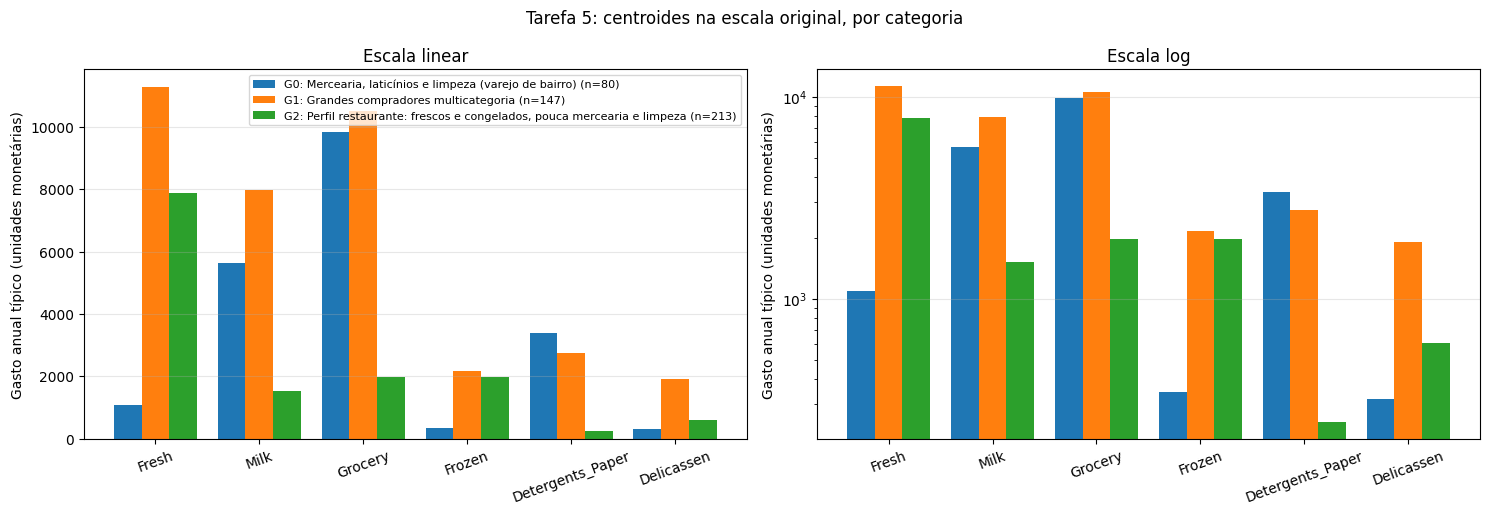

In [14]:
# --- (a) Centroides revertidos para a escala original ---------------------------
# Desfaz a padronização e depois o log:  x = expm1( z*desvio + média )
# ATENÇÃO: o centroide em escala log, ao ser revertido, vira algo próximo da
# MÉDIA GEOMÉTRICA do grupo (valor "típico"); fica abaixo da média aritmética
# quando há cauda longa. Mostramos as duas para comparação.
z_cent = pd.DataFrame(km_k.cluster_centers_, columns=GASTOS)
cent_orig = pd.DataFrame(np.expm1(escalador.inverse_transform(km_k.cluster_centers_)), columns=GASTOS)
medias_aritm = X.groupby(rotulos).mean()

nomes = {g: nomear(z_cent.loc[g]) for g in range(K_ESCOLHIDO)}
for g in range(K_ESCOLHIDO):
    print(f"Grupo {g}: {nomes[g]}")

print("\nCentroides em ESCALA Z (desvios padrão em relação à média geral):")
print(z_cent.round(2))
print("\nCentroides revertidos para a ESCALA ORIGINAL (típico do grupo):")
print(cent_orig.round(0).astype(int))
print("\nMédias aritméticas por grupo (escala original, para comparação):")
print(medias_aritm.round(0).astype(int))

# Gráfico de barras agrupadas por categoria (escala linear e logarítmica)
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.2))
largura = 0.8 / K_ESCOLHIDO
posicoes = np.arange(len(GASTOS))
for ax, escala in zip(eixos, ("linear", "log")):
    for g in range(K_ESCOLHIDO):
        ax.bar(posicoes + g * largura, cent_orig.loc[g].values, width=largura,
               label=f"G{g}: {nomes[g]} (n={tamanhos[g]})")
    ax.set_xticks(posicoes + largura * (K_ESCOLHIDO - 1) / 2, GASTOS, rotation=20)
    ax.set_yscale(escala)
    ax.set_ylabel("Gasto anual típico (unidades monetárias)")
    ax.set_title(f"Escala {escala}")
    ax.grid(alpha=0.3, axis="y")
eixos[0].legend(fontsize=8)
fig.suptitle("Tarefa 5: centroides na escala original, por categoria")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t5_centroides.png", dpi=150)
plt.show()

In [16]:
# --- (b) Validação externa: tabelas de contingência e ARI -----------------------
canal_nome = canal.map(NOME_CANAL)
regiao_nome = regiao.map(NOME_REGIAO)
cont_canal = pd.crosstab(pd.Series(rotulos, name="grupo"), canal_nome.rename("Canal"))
cont_regiao = pd.crosstab(pd.Series(rotulos, name="grupo"), regiao_nome.rename("Região"))
print("\nTabela de contingência: grupo x CANAL (contagens)")
print(cont_canal)
print("\n% do canal em cada grupo (colunas somam 100%):")
print((cont_canal / cont_canal.sum() * 100).round(1))
print("\n% de cada grupo por canal (linhas somam 100%):")
print((cont_canal.div(cont_canal.sum(axis=1), axis=0) * 100).round(1))

print("\nTabela de contingência: grupo x REGIÃO (contagens)")
print(cont_regiao)
print("\n% de cada grupo por região (linhas somam 100%):")
print((cont_regiao.div(cont_regiao.sum(axis=1), axis=0) * 100).round(1))
print("% da base total por região:",
      (regiao_nome.value_counts(normalize=True) * 100).round(1).to_dict())

ari_canal = adjusted_rand_score(canal, rotulos)
ari_regiao = adjusted_rand_score(regiao, rotulos)
print(f"\nÍndice Rand ajustado (ARI) grupos x Channel : {ari_canal:.4f}")
print(f"Índice Rand ajustado (ARI) grupos x Region  : {ari_regiao:.4f}")

# Referência: com k = 2 (mesmo número de classes do canal)
km2 = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=SEED).fit(Z)
print(f"ARI com k = 2 x Channel (referência)        : {adjusted_rand_score(canal, km2.labels_):.4f}")
cont2 = pd.crosstab(pd.Series(km2.labels_, name="grupo (k=2)"), canal_nome.rename("Canal"))
print("\nContingência grupo (k=2) x Canal:")
print(cont2)

# Teste de independência entre grupo e região (qui-quadrado) + V de Cramér
chi2, p_valor, gl, _ = chi2_contingency(cont_regiao)
n = cont_regiao.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n * (min(cont_regiao.shape) - 1)))
print(f"\nGrupo x Região: qui-quadrado = {chi2:.2f}, gl = {gl}, p = {p_valor:.3f}, "
      f"V de Cramér = {v_cramer:.3f}")
chi2_c, p_c, gl_c, _ = chi2_contingency(cont_canal)
v_c = np.sqrt(chi2_c / (n * (min(cont_canal.shape) - 1)))
print(f"Grupo x Canal : qui-quadrado = {chi2_c:.2f}, gl = {gl_c}, p = {p_c:.2e}, "
      f"V de Cramér = {v_c:.3f}")


Tabela de contingência: grupo x CANAL (contagens)
Canal  Horeca  Retail
grupo                
0          32      48
1          56      91
2         210       3

% do canal em cada grupo (colunas somam 100%):
Canal  Horeca  Retail
grupo                
0        10.7    33.8
1        18.8    64.1
2        70.5     2.1

% de cada grupo por canal (linhas somam 100%):
Canal  Horeca  Retail
grupo                
0        40.0    60.0
1        38.1    61.9
2        98.6     1.4

Tabela de contingência: grupo x REGIÃO (contagens)
Região  Lisboa  Outras  Porto
grupo                        
0           14      56     10
1           23     113     11
2           40     147     26

% de cada grupo por região (linhas somam 100%):
Região  Lisboa  Outras  Porto
grupo                        
0         17.5    70.0   12.5
1         15.6    76.9    7.5
2         18.8    69.0   12.2
% da base total por região: {'Outras': 71.8, 'Lisboa': 17.5, 'Porto': 10.7}

Índice Rand ajustado (ARI) grupos x Channel :

In [18]:
# --- (c) Quais categorias mais separam Horeca de Retail? ------------------------
# Diferença padronizada de médias (d de Cohen) sobre os gastos em log + Z-score:
# d > 0 -> Retail gasta mais; d < 0 -> Horeca gasta mais.
Zdf = pd.DataFrame(Z, columns=GASTOS)
g_h, g_r = Zdf[canal == 1], Zdf[canal == 2]
dp_comb = np.sqrt(((len(g_h) - 1) * g_h.var() + (len(g_r) - 1) * g_r.var())
                  / (len(g_h) + len(g_r) - 2))
d_cohen = ((g_r.mean() - g_h.mean()) / dp_comb).sort_values(key=np.abs, ascending=False)
print("\nSeparação Horeca x Retail por categoria (d de Cohen; + = Retail gasta mais):")
print(d_cohen.round(2).to_string())
print("\nGasto mediano por canal (escala original):")
print(X.groupby(canal_nome).median().round(0).astype(int))


Separação Horeca x Retail por categoria (d de Cohen; + = Retail gasta mais):
Detergents_Paper    2.26
Grocery             1.89
Milk                1.51
Frozen             -0.54
Fresh              -0.37
Delicassen          0.28

Gasto mediano por canal (escala original):
         Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Channel                                                            
Horeca    9582  2157     2684    2058               386         821
Retail    5994  7812    12390    1081              5614        1350



PCA: variância explicada pelos 2 componentes = [0.441 0.272] (soma 71.3%)
Cargas dos componentes:
                   PC1   PC2
Fresh            -0.11  0.59
Milk              0.54  0.13
Grocery           0.57 -0.01
Frozen           -0.14  0.59
Detergents_Paper  0.55 -0.07
Delicassen        0.21  0.53


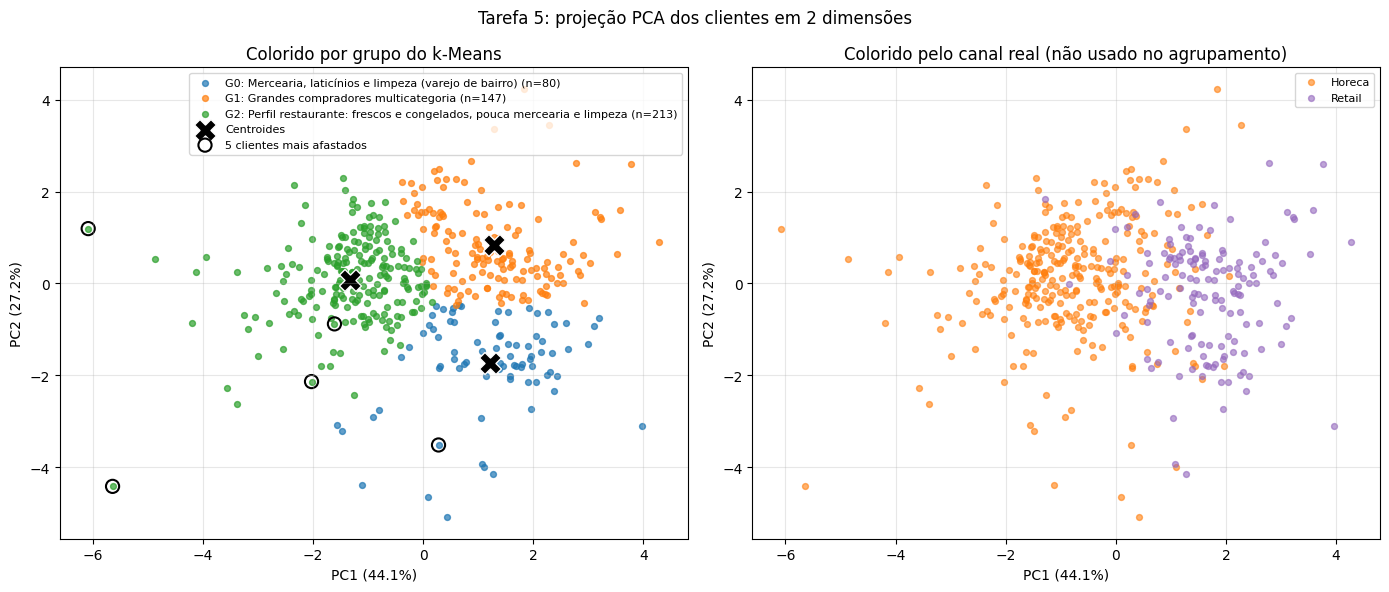

In [19]:
# --- (d) PCA em 2D ---------------------------------------------------------------
pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(Z)
print(f"\nPCA: variância explicada pelos 2 componentes = "
      f"{pca.explained_variance_ratio_.round(3)} (soma {pca.explained_variance_ratio_.sum():.1%})")
cargas = pd.DataFrame(pca.components_.T, index=GASTOS, columns=["PC1", "PC2"])
print("Cargas dos componentes:")
print(cargas.round(2))
cent2 = pca.transform(km_k.cluster_centers_)

# Distância de cada cliente ao centroide do seu grupo (no espaço padronizado)
dist_centroide = np.linalg.norm(Z - km_k.cluster_centers_[rotulos], axis=1)
idx_outliers = np.argsort(dist_centroide)[-5:]  # 5 clientes mais afastados

cores = plt.cm.tab10(np.arange(K_ESCOLHIDO))
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))
for g in range(K_ESCOLHIDO):
    m = rotulos == g
    eixos[0].scatter(Z2[m, 0], Z2[m, 1], s=18, color=cores[g], alpha=0.7,
                     label=f"G{g}: {nomes[g]} (n={tamanhos[g]})")
eixos[0].scatter(cent2[:, 0], cent2[:, 1], marker="X", s=250, c="black", edgecolors="white",
                 label="Centroides")
eixos[0].scatter(Z2[idx_outliers, 0], Z2[idx_outliers, 1], s=90, facecolors="none",
                 edgecolors="black", linewidths=1.5, label="5 clientes mais afastados")
eixos[0].set_title("Colorido por grupo do k-Means")
for cod, cor in ((1, "tab:orange"), (2, "tab:purple")):
    m = (canal == cod).to_numpy()
    eixos[1].scatter(Z2[m, 0], Z2[m, 1], s=18, color=cor, alpha=0.6, label=NOME_CANAL[cod])
eixos[1].set_title("Colorido pelo canal real (não usado no agrupamento)")
for ax in eixos:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Tarefa 5: projeção PCA dos clientes em 2 dimensões")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t5_pca.png", dpi=150)
plt.show()

In [21]:
# --- (e) Evidências das limitações do k-Means -------------------------------------
print("\nLimitação 1 - geometria esférica e tamanhos semelhantes:")
print(f"  tamanhos dos grupos: {dict(enumerate(tamanhos.tolist()))} "
      f"(razão maior/menor = {tamanhos.max() / tamanhos.min():.1f})")
dp_dist = pd.Series(dist_centroide).groupby(rotulos).agg(["mean", "max"])
print("  distância ao centroide por grupo (espaço padronizado):")
print(dp_dist.round(2))
print(f"  silhueta média = {s_amostra.mean():.3f} (valores < 0,5 indicam grupos que se tocam)")

print("\nLimitação 2 - sensibilidade a outliers:")
corte = np.percentile(dist_centroide, 95)
manter = dist_centroide <= corte
km_sem = KMeans(n_clusters=K_ESCOLHIDO, init="k-means++", n_init=10, random_state=SEED).fit(Z[manter])
# casa os grupos antes/depois pelo centroide mais próximo (algoritmo húngaro)
custo = np.linalg.norm(km_k.cluster_centers_[:, None, :] - km_sem.cluster_centers_[None, :, :], axis=2)
lin, col = linear_sum_assignment(custo)
deslocamento = custo[lin, col]
print(f"  removidos {(~manter).sum()} clientes (5% mais afastados) e refeito o agrupamento")
print(f"  deslocamento dos centroides (unidades de desvio padrão): "
      f"{dict(zip(lin.tolist(), deslocamento.round(3).tolist()))}")
print(f"  ARI entre o agrupamento original e o refeito (nos {manter.sum()} clientes restantes): "
      f"{adjusted_rand_score(rotulos[manter], km_sem.predict(Z[manter])):.3f}")
print(f"  inércia por cliente: antes = {km_k.inertia_ / len(Z):.3f} | "
      f"depois = {km_sem.inertia_ / manter.sum():.3f}")

# Efeito dos outliers SEM a transformação log (dados brutos padronizados)
Z_bruto = StandardScaler().fit_transform(X)
km_bruto = KMeans(n_clusters=K_ESCOLHIDO, init="k-means++", n_init=10, random_state=SEED).fit(Z_bruto)
print(f"\n  Sem log (apenas Z-score nos dados brutos), tamanhos dos grupos: "
      f"{np.sort(np.bincount(km_bruto.labels_))[::-1].tolist()}")
print(f"  -> ARI entre esse agrupamento e o do pipeline log + Z-score: "
      f"{adjusted_rand_score(rotulos, km_bruto.labels_):.3f}")



Limitação 1 - geometria esférica e tamanhos semelhantes:
  tamanhos dos grupos: {0: 80, 1: 147, 2: 213} (razão maior/menor = 2.7)
  distância ao centroide por grupo (espaço padronizado):
   mean   max
0  2.07  4.25
1  1.57  4.08
2  1.65  6.26
  silhueta média = 0.259 (valores < 0,5 indicam grupos que se tocam)

Limitação 2 - sensibilidade a outliers:
  removidos 22 clientes (5% mais afastados) e refeito o agrupamento
  deslocamento dos centroides (unidades de desvio padrão): {0: 0.537, 1: 0.163, 2: 0.176}
  ARI entre o agrupamento original e o refeito (nos 418 clientes restantes): 0.872
  inércia por cliente: antes = 3.531 | depois = 2.767

  Sem log (apenas Z-score nos dados brutos), tamanhos dos grupos: [393, 45, 2]
  -> ARI entre esse agrupamento e o do pipeline log + Z-score: 0.084
